[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/loem-ms/programming-for-information-systems-site/blob/main/content/downloads/Week_08.ipynb) · [Setup and saving](https://loem-ms.github.io/programming-for-information-systems-site/content/setup/)

**Before editing: File → Save a copy in Drive.** Support files are embedded; setup appears at their first use.


# Week 08 · JSON values and dictionary checks

<a id="start"></a>
[Warm-up](#class-warm-up) · [Session 1](#session-1) · [Session 2](#session-2) · [Session 3](#project-studio)


## Class warm-up · Research 6 exchange
<a id="class-warm-up"></a>

Share your already prepared Research 6 response about **checking automated or AI output**. Compare a source statement, an automated claim and the evidence that supports or contradicts it. Keep your source, one question or useful feedback, and your own response. This closes the previously assigned research task; it adds no new assignment.

**My feedback and next step:** …


## Session 1 · Python foundations
<a id="session-1"></a>


### JSON text and Python values

JSON is a text format. `loads` parses it into a Python value. An object becomes a dictionary, an array a list, `null` becomes `None`, and `true` becomes `True`.

```python
import json
print(json.loads("[1, true, null]"))  # [1, True, None]
```


### Syntax and shape

Valid JSON may have the wrong shape for your program. Malformed JSON raises `JSONDecodeError`.

```python
import json
print(type(json.loads("[]")).__name__)  # list, not dict
```


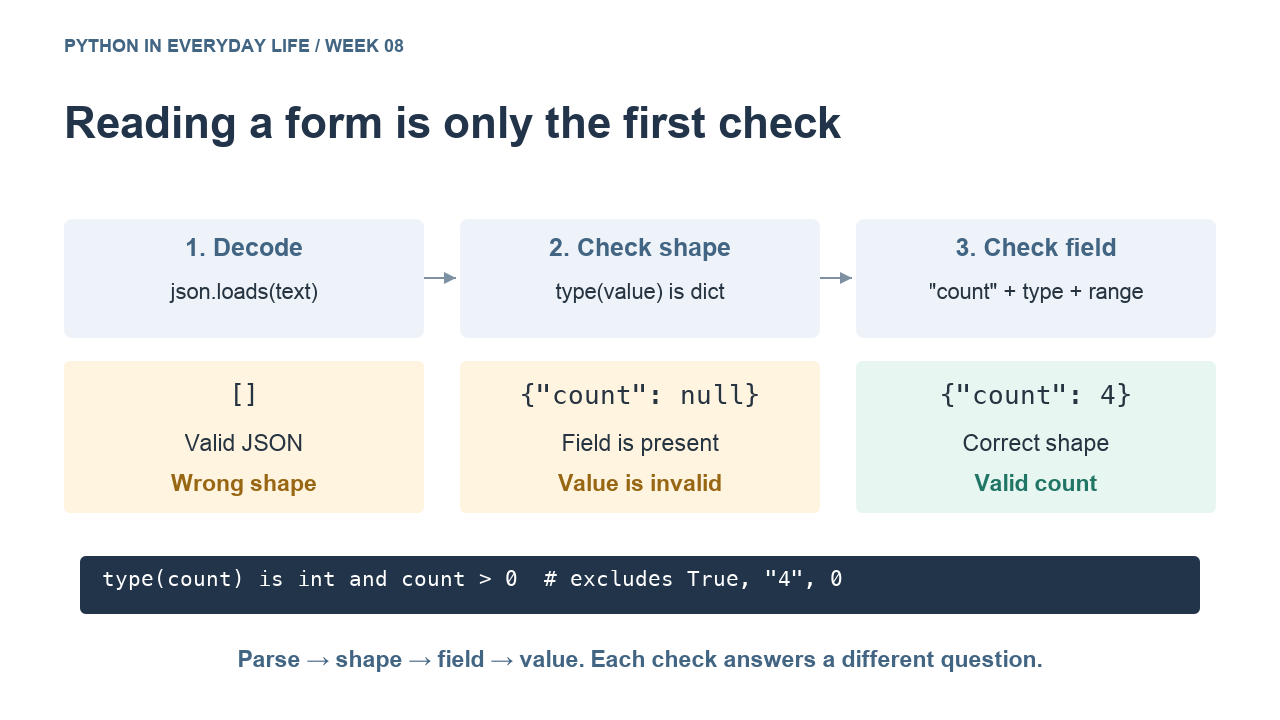


### Field presence

Check the outer type before dictionary operations. `get` returns `None` for a missing field; indexing a missing key raises `KeyError`.

```python
candidate = {"count": 4}
print("count" in candidate, candidate.get("missing"))  # True None
```


### Exact types

Under a positive exact-integer contract, `True`, `"4"` and `4.0` are invalid. `bool` is a subclass of `int`, so `isinstance` alone is too broad.

```python
value = True
print(isinstance(value, int), type(value) is int)  # True False
```


### Short-circuit checks

`and` checks the range only after the type check succeeds. Reversing that order could compare text or `None` with a number.

```python
value = None
print(type(value) is int and value > 0)  # False, without a TypeError
```


### Parsing and approval

A parser checks syntax; a validator checks the contract. Neither establishes whether a proposed real-world action is approved.

```python
candidate = {"count": 4}
valid = type(candidate.get("count")) is int and candidate["count"] > 0
```


### Example 1 · Decode one JSON value at a time

JSON text is a string; `json.loads` returns a Python value. Predict `dict`, `list` and `NoneType`. Parsing alone does not prove that a value has the shape your program needs.


In [ ]:
import json
print(type(json.loads('{"count": 4}')).__name__)
print(type(json.loads('[]')).__name__)
print(type(json.loads('null')).__name__)


### Example 2 · Check shape before reading a key

A list and a dictionary both parse successfully, but only the dictionary has the expected named field. Test the outer shape before calling `get`. Predict Object required. This check is independent of a count-range check.


In [ ]:
import json
candidate = json.loads('[]')
if type(candidate) is not dict:
    print("Object required")
else:
    print(candidate.get("count"))


### Example 3 · Distinguish a missing key from an invalid value

The `in` operator checks whether a dictionary has a key. A present key with `null` becomes `None`; it is present but invalid for the positive-integer contract. Predict `True`, `None`, `False`.


In [ ]:
import json
candidate = json.loads('{"count": null}')
print("count" in candidate)
value = candidate.get("count")
print(value)
print(type(value) is int and value > 0)


### Example 4 · Catch malformed JSON specifically

A `JSONDecodeError` means parsing could not produce a value. Catch it separately from later shape and field checks. Predict Invalid JSON. Keep the original text as evidence.


In [ ]:
import json
text = "{"
try:
    value = json.loads(text)
except json.JSONDecodeError:
    print("Invalid JSON")


### Combined example


In [ ]:
import json

texts = ['{"count": 4}', '[]', 'null', '{"count": true}']
observed = []
for text in texts:
    candidate = json.loads(text)
    print("Shape:", type(candidate).__name__)
    if type(candidate) is dict:
        count = candidate.get("count")
        valid = type(count) is int and count > 0
        observed.append(valid)
        print("Count:", repr(count), "Valid:", valid)
assert observed == [True, False]


The shapes are `dict`, `list`, `NoneType` and `dict`. Only dictionaries enter the field-reading block. The count checks produce `True` for 4 and `False` for `True`. Every input is valid JSON, but only the first meets the stated contract.

## Session 2 · Hands-on practice
<a id="session-2"></a>
<a id="practice-week-08"></a>

Five exercises: P1–P3 are core; P4–P5 are optional. Record an expected result, observed result and explanation for each completed exercise.


### P1 · Decode and name the shape

**Core**

Write your own code for exactly these three JSON strings: `'{"containers": 4}'`, `'[]'`, and `'null'`. Import `json`, decode each string, and print its Python type name. Predict `dict`, `list` and `NoneType` before running. Hint: `json.loads` returns a value; `type(value).__name__` names its type. These are practice inputs, not a ready-made solution. No validation function is needed yet.


In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P2 · Write a count predicate

**Core**

Easy. Write `valid_count(value)` returning a Boolean. Accept only a positive exact integer. Predict results for 4, 0, `True`, `"4"` and `None` before coding. Hint: test the type before the range and combine with `and`. Write one assertion for each input.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P3 · Build a proposal validator

**Core**

Write `inspect_proposal(text)`. Return a dictionary with `disposition`, `reason` and `containers`. Check in this order: malformed JSON → `rejected` / `invalid JSON` / `None`; non-dictionary → `rejected` / `object required` / `None`; missing `containers` key → `rejected` / `missing containers` / `None`; invalid count → `rejected` / `positive integer required` / `None`; positive exact integer → `proposed` / `coordinator review needed` / the count.

Use these exact JSON strings as your six inputs, in order:

1. `'{'` (malformed text)
2. `'[]'` (the wrong outer shape)
3. `'{}'` (missing field)
4. `'{"containers": true}'` (Boolean count)
5. `'{"containers": 0}'` (nonpositive count)
6. `'{"containers": 4}'` (valid count)

Write an independent expected dictionary for every case, then implement and test all branches. The last three inputs are JSON objects, not the standalone JSON values `true`, 0 and 4. No reservation or database change occurs.


In [ ]:
import json

def inspect_proposal(text):
    # Write parsing, ordered checks and the result dictionaries.
    raise NotImplementedError

# Predict expected reasons independently, then write tests.


**Expected:** …  **Observed:** …  **Explanation:** …


### P4 · Keep source IDs in an audit list

**Optional**

Using your validator, write `audit_messages(messages)`. For each `(message_id,text)`, append a `dict` with `message_id`, `original_text` and `result` (the validator `dict`). Preserve input order and every message, including rejected ones. Test two messages: M1 with count 4 and M2 with `[]`. Expect two records, `proposed` then `rejected`, and unchanged original text.

In [ ]:
messages = [("M1", '{"containers": 4}'), ("M2", '[]')]
# Reuse inspect_proposal. Write audit_messages and assertions.


**Expected:** …  **Observed:** …  **Explanation:** …


### P5 · Write tests that catch a relaxed contract

**Optional**

Write a test loop for `4.0`, `"4"`, `-1` and `null` container values. Every result must be `rejected` with `positive integer required` and `containers` `None`. Then use a separate copy with `isinstance(value,int)` in place of exact type. Add the `true` case to expose the wrong acceptance. Keep the correct implementation and explain why adding `int(value)` changes the contract.

In [ ]:
# Reuse inspect_proposal. Write your edge-case test loop.
# Make any deliberately wrong implementation a separate copy.


**Expected:** …  **Observed:** …  **Explanation:** …


Optional: add your own adversarial JSON case, predict its reason, then check the validator without relaxing the contract. Actual HTTP work remains in Session 3.

## Session 3 · Project studio
<a id="project-studio"></a>


### Project files

Run this collapsed cell once, and again after a runtime restart. No ZIP, upload or network download is needed. Existing support files are preserved. Save created or edited files separately.


In [ ]:
# @title Prepare the course files (run after each runtime restart)
# Supplied programs, starter policy, CSV fixtures and diagrams are embedded here.
# This cell uses only Python's standard library. It makes no network request.
import base64 as _course_base64
import hashlib as _course_hashlib
import json as _course_json
import os as _course_os
from pathlib import Path as _CoursePath
import zlib as _course_zlib

_course_payload = '...'
_course_raw = _course_zlib.decompress(_course_base64.b64decode(_course_payload))
if _course_hashlib.sha256(_course_raw).hexdigest() != 'af476d628f248123db85949bf75d45f3d73fba532a9d4ff6261f1e7199e11738':
    raise ValueError("Embedded course files are damaged; get a fresh notebook.")
_course_files = _course_json.loads(_course_raw)
_course_key = 'week_08_af476d628f24'
_course_roots = globals().setdefault("_course_workspace_roots", {})
if _course_key in _course_roots:
    _course_root = _CoursePath(_course_roots[_course_key])
elif all((_CoursePath.cwd() / _name).is_file() for _name in _course_files):
    # A complete extracted offline pack can be used in place.
    _course_root = _CoursePath.cwd()
else:
    _course_root = _CoursePath.cwd() / ".course_files" / _course_key
if _course_root.is_symlink() or any(_p.is_symlink() for _p in _course_root.parents):
    raise ValueError("Refusing a symbolic link in the course workspace")
_course_root.mkdir(parents=True, exist_ok=True)
for _name, _encoded in _course_files.items():
    _relative = _CoursePath(_name)
    if _relative.is_absolute() or ".." in _relative.parts:
        raise ValueError("Unsafe embedded support path")
    _target = _course_root / _relative
    if _target.is_symlink() or any(_p.is_symlink() for _p in _target.parents):
        raise ValueError("Refusing a symbolic link in the course workspace")
    _target.parent.mkdir(parents=True, exist_ok=True)
    if _target.exists() and not _target.is_file():
        raise ValueError("Course support path is not a regular file: " + str(_target))
    if not _target.exists():
        with _target.open("xb") as _output:
            _output.write(_course_base64.b64decode(_encoded))
_course_workspace_roots[_course_key] = str(_course_root.resolve())
_course_os.chdir(_course_root)
print("Course files ready:", _CoursePath.cwd())
print("Existing files were kept. Rerunning setup never replaces your edits.")
print("Save your notebook and download created/edited files before the runtime ends.")


### The people’s task this week

**Someone needs help:** The coordinator needs to distinguish promises from actual events.

**Your small part:** Compare pickup records and review incoming messages before using their claims.

![Week 8: the person’s need, your task, and the useful result.](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/assets/diagrams/course_week_08.svg)

**Picture one example:** Collected, but not delivered → follow up.

**A useful result:** The coordinator knows which pickups need follow-up.

Use the supplied starting files and the task instructions below. The diagram explains the purpose; it adds no separate assignment.

**Final-project connection:** Prepare to reproduce the supplied final notebook from clean inputs. Note one input, the processing rule and its output. Choose one small decision to explain in the existing final notes; implementing a change is optional.


In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/course_week_08.svg'))


### Project application reference examples

These saved lesson examples support the project tasks below. Run the one you need; Python core practice is in Session 2.

**Miniature SQL ledger: an independent fixture for the grouping practice**

In [ ]:
import sqlite3
db = sqlite3.connect(":memory:")
db.execute("CREATE TABLE lines(request_id TEXT, batch_id TEXT, containers INT, ppc INT)")
db.executemany("INSERT INTO lines VALUES (?, ?, ?, ?)",
    [("D01", "T10", 2, 3), ("D01", "T20", 1, 4), ("D02", "T10", 1, 3)])
query = """SELECT batch_id, SUM(containers) AS containers,
       SUM(containers * ppc) AS planned_portions
FROM lines
GROUP BY batch_id
ORDER BY batch_id;"""
rows = db.execute(query).fetchall()
print(rows)
assert rows == [("T10", 3, 9), ("T20", 1, 4)]
db.close()


**Offline failure practice — no HTTP request is made**

This supplies the `fetch` context needed by the slide excerpt. Change `fetch` to return a small dictionary to try the success path. Actual HTTP evidence is completed in [Project Studio below](#project-studio).

In [ ]:
from urllib.error import HTTPError
message_id = "PRACTICE"
def fetch(message_id):
    raise HTTPError("https://example.invalid/practice", 503, "simulated", None, None)

from urllib.error import HTTPError
queue = []
try:
    candidate = fetch(message_id)  # supplied context
except HTTPError as error:
    queue.append({"message_id": message_id,
                  "reason": f"HTTP {error.code}",
                  "next_action": "coordinator follow-up"})
assert len(queue) == 1
print(queue)


### Project context

The fictional records distinguish planning, reservation, collection and delivery. Counts are not people served. Human review remains separate from parsing. The required HTTP exercise uses the supplied local service; offline simulation is separate evidence.



### The coordinator needs evidence, not an impressive total

Last week, a reservation became an all-or-nothing promise: either every reviewed pickup line reserved containers, or nothing changed. Now the coordinator asks what was offered, reserved, collected and delivered. The donor liaison also receives an ambiguous message. A reservation is not collection; a candidate message is not a reviewed offer.

| Starting evidence | Next steps | Required distinction |
|---|---|---|
| Reviewed offered containers | Reserve; record collection; record delivery | Each stage needs its own evidence |
| Donor message | Extract candidate fields; clarify; prepare a proposal; obtain human review | Candidate data is not reservable availability |

**Predict:** could the team add offered, reserved and delivered portions to report “total impact”? Explain the double counting before reading further.

### Define and trace a measure

Compare Research Assignment 6 examples. Define a planning measure and trace one reservation and one donor claim.

### 1. Make the unit and lifecycle stage explicit

A line has container count and a snapshot of declared portions per container. Multiply them for planned portions. Neither number proves how many distinct people ate or verifies suitability.

| Measure | Evidence | What it does not establish |
|---|---|---|
| Offered | Reviewed opening batch counts | Reserved, collected or delivered |
| Reserved | Accepted reservation lines | Physical collection |
| Collected | Explicit whole-reservation collection event | Delivery |
| Delivered | Collection followed by delivery event | Distinct people served or nutrition |

These lifecycle measures overlap. For this teaching fixture each event covers a whole reservation; partial collection/delivery is out of scope. Use separate status buckets if you need an additive reconciliation.

![Canonical fixture lifecycle: offered 94, reserved 60, collected 42 and delivered 29 are overlapping measures.](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/assets/diagrams/w08_evidence.svg)

*This figure shows the full shared fixture. The supplied miniature ledger in this Project studio section uses different practice data and totals thirteen planned portions.*


In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w08_evidence.svg'))


### Report and prepare

Use SQL to report reservations and explicit lifecycle events. Prepare to reproduce the supplied final notebook and explain two expected outcomes. Choose one small decision, an alternative and two contrasting cases for the existing final decision note; implementation is optional.

**Your decision, within the existing notes:** Own one small meaningful decision: a threshold, a rule, or information wording/display. In the existing decision note, state the user and context, your choice, one alternative, your reason, a tradeoff or consequence, and two contrasting cases. Keeping the supplied setting is valid if you explain why it fits. There is no single preferred threshold or design. Correct calculations, human review, declared units, atomic reservations and honest event evidence remain fixed. Label proposed/paper behavior separately from implemented results. No code change, new feature, custom UI or extra slide deck is required. Presentations can differ through your choice, rationale and examples even with the same engine.


### 3. Load the shared fixture and supplied baseline

The three CSVs are authoritative. A row in `pickup_requests.csv` is a line, so group lines by request ID before reserving. A review flag records an invented coordinator decision; the program does not infer suitability. The supplied baseline gives this week's report a complete dataset and preserves snapshot portions on each line.

Read the transaction boundary and the event guard. A failed later line must undo the header, earlier line and earlier availability change. A delivery is rejected unless collection already exists. This baseline is supplied infrastructure for your reporting task, not a new requirement to rewrite Week 7.

In [ ]:
from pathlib import Path
import csv

def fixture_directory():
    for candidate in (Path("final-data"), Path("learning_materials/final-data"), Path("../learning_materials/final-data")):
        if (candidate / "offer_batches.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Keep learning_materials/final-data with the teaching materials")

DATA_DIR = fixture_directory()

def read_fixture():
    with (DATA_DIR / "offer_batches.csv").open(encoding="utf-8", newline="") as file:
        batches = [(row["batch_id"], row["description"], int(row["portions_per_container"]),
                    int(row["opening_available"])) for row in csv.DictReader(file)]
    grouped = {}
    with (DATA_DIR / "pickup_requests.csv").open(encoding="utf-8", newline="") as file:
        for row in csv.DictReader(file):
            if row["reviewed"] not in ("yes", "no"):
                raise ValueError("reviewed must be yes or no")
            reviewed = row["reviewed"] == "yes"
            request = grouped.setdefault(row["request_id"], {"reviewed": reviewed, "lines": []})
            if request["reviewed"] != reviewed:
                raise ValueError("conflicting review flags within one request")
            request["lines"].append((row["batch_id"], int(row["containers"])))
    requests = [(request_id, item["reviewed"], item["lines"])
                for request_id, item in grouped.items()]
    with (DATA_DIR / "rescue_events.csv").open(encoding="utf-8", newline="") as file:
        events = [(row["request_id"], row["event_type"]) for row in csv.DictReader(file)]
    return batches, requests, events

batches, requests, events = read_fixture()
print("Fixture:", len(batches), "batches;", len(requests), "requests;", len(events), "events")

### Supplied setup: run once, then continue

**No editing required in the engine below.** Run the fixture-loading cell above, then run this supplied engine cell to create the known starting database. Rerunning it resets the fixture; it does not retry an operation against the previous state.

The implementation may be collapsed by your notebook viewer. You may inspect it later, but your task is the behavior requested next. After setup, [continue to your project task](#project-task).

In [ ]:
import sqlite3

def pickup_label(total_portions, reviewed):
    if type(total_portions) is not int or total_portions < 0 or type(reviewed) is not bool:
        raise ValueError("expected nonnegative integer portions and a Boolean review flag")
    if not reviewed:
        return "hold"
    return "team" if total_portions >= 20 else "standard"

def new_rescue_db(batch_rows):
    db = sqlite3.connect(":memory:")
    db.execute("PRAGMA foreign_keys=ON")
    db.executescript("""
        CREATE TABLE batches(
            batch_id TEXT PRIMARY KEY, description TEXT,
            portions_per_container INTEGER CHECK(portions_per_container>0),
            opening_available INTEGER CHECK(opening_available>=0),
            available INTEGER CHECK(available>=0));
        CREATE TABLE reservations(
            request_id TEXT PRIMARY KEY, reviewed INTEGER CHECK(reviewed=1),
            label TEXT, planned_portions INTEGER CHECK(planned_portions>0));
        CREATE TABLE reservation_lines(
            request_id TEXT REFERENCES reservations(request_id), line_no INTEGER,
            batch_id TEXT REFERENCES batches(batch_id), containers INTEGER CHECK(containers>0),
            portions_per_container INTEGER CHECK(portions_per_container>0),
            PRIMARY KEY(request_id,line_no));
        CREATE TABLE events(
            request_id TEXT REFERENCES reservations(request_id),
            event_type TEXT CHECK(event_type IN ('collected','delivered')),
            PRIMARY KEY(request_id,event_type));
    """)
    with db:
        for batch_id, description, portions, available in batch_rows:
            if type(portions) is not int or portions <= 0 or type(available) is not int or available < 0:
                raise ValueError("invalid batch planning counts")
            db.execute("INSERT INTO batches VALUES (?,?,?,?,?)",
                       (batch_id, description, portions, available, available))
    return db

def reserve(db, request_id, reviewed, lines, inject_failure=False):
    if type(reviewed) is not bool or not reviewed:
        raise ValueError("coordinator review required")
    if not lines or any(type(count) is not int or count <= 0 for batch, count in lines):
        raise ValueError("reservation needs positive whole container counts")
    with db:
        prepared = []
        for batch_id, containers in lines:
            batch = db.execute("SELECT portions_per_container FROM batches WHERE batch_id=?",
                               (batch_id,)).fetchone()
            if batch is None:
                raise ValueError(f"unknown batch {batch_id}")
            prepared.append((batch_id, containers, batch[0]))
        total = sum(containers * portions for batch_id, containers, portions in prepared)
        label = pickup_label(total, reviewed)
        db.execute("INSERT INTO reservations VALUES (?,?,?,?)", (request_id, 1, label, total))
        for index, (batch_id, containers, portions) in enumerate(prepared, start=1):
            change = db.execute("UPDATE batches SET available=available-? WHERE batch_id=? AND available>=?",
                                (containers, batch_id, containers))
            if change.rowcount != 1:
                raise ValueError(f"insufficient available containers for {batch_id}")
            db.execute("INSERT INTO reservation_lines VALUES (?,?,?,?,?)",
                       (request_id, index, batch_id, containers, portions))
            if inject_failure and index == 1:
                raise RuntimeError("deliberate failure after first reservation line")
    return label

def record_event(db, request_id, event_type):
    if event_type not in ("collected", "delivered"):
        raise ValueError("unknown event type")
    with db:
        if db.execute("SELECT 1 FROM reservations WHERE request_id=?", (request_id,)).fetchone() is None:
            raise ValueError("event needs an accepted reservation")
        if event_type == "delivered" and db.execute(
            "SELECT 1 FROM events WHERE request_id=? AND event_type='collected'", (request_id,)
        ).fetchone() is None:
            raise ValueError("record collection before delivery")
        db.execute("INSERT INTO events VALUES (?,?)", (request_id, event_type))

def snapshot(db):
    # Table names are fixed teaching constants, never user-supplied SQL.
    return tuple(tuple(db.execute(f"SELECT * FROM {table} ORDER BY 1,2").fetchall())
                 for table in ("batches", "reservations", "reservation_lines", "events"))

def build_fixture(batch_rows, request_rows, event_rows):
    db = new_rescue_db(batch_rows)
    decisions = []
    for request_id, reviewed, lines in request_rows:
        before = snapshot(db)
        try:
            label = reserve(db, request_id, reviewed, lines)
        except ValueError as error:
            assert snapshot(db) == before
            decisions.append((request_id, "held" if not reviewed else "rejected", str(error)))
        else:
            decisions.append((request_id, "accepted", label))
    for request_id, event_type in event_rows:
        record_event(db, request_id, event_type)
    return db, decisions

# Rerunning this cell starts a new database; it does not retry against old state.
if "rescue_db" in globals():
    rescue_db.close()
rescue_db, decisions = build_fixture(batches, requests, events)
print("Reservation decisions:", decisions)

### Example 1 · Aggregate before joining evidence

`SUM` adds values and `GROUP BY` separates the totals by category. Predict A 5 and B 4. An empty `SUM` is `None`; `COALESCE` supplies zero for an empty result. These SQL operations are independent of project lifecycle rules.


In [ ]:
import sqlite3
example_db = sqlite3.connect(":memory:")
try:
    example_db.execute("CREATE TABLE scores(category TEXT, points INTEGER)")
    example_db.executemany("INSERT INTO scores VALUES (?, ?)", [("A", 2), ("A", 3), ("B", 4)])
    rows = example_db.execute("SELECT category, SUM(points) FROM scores GROUP BY category ORDER BY category").fetchall()
    print(rows)
    empty_total = example_db.execute("SELECT COALESCE(SUM(points), 0) FROM scores WHERE category = ?", ("missing",)).fetchone()[0]
    print(empty_total)
    assert rows == [("A", 5), ("B", 4)] and empty_total == 0
finally:
    example_db.close()


### Example 2 · Use `EXISTS` without multiplying source rows

The `marks` table has two matching rows for A. `EXISTS` asks only whether a match exists; it does not duplicate A before `SUM`. Predict 3, not 6. `AS` gives each table a short local name; `r.id` and `m.record_id` identify the matching columns.


In [ ]:
import sqlite3
example_db = sqlite3.connect(":memory:")
try:
    example_db.executescript("CREATE TABLE records(id TEXT, amount INTEGER); CREATE TABLE marks(record_id TEXT, label TEXT);")
    example_db.executemany("INSERT INTO records VALUES (?, ?)", [("A", 3), ("B", 5)])
    example_db.executemany("INSERT INTO marks VALUES (?, ?)", [("A", "checked"), ("A", "confirmed")])
    total = example_db.execute("SELECT SUM(r.amount) FROM records AS r WHERE EXISTS (SELECT 1 FROM marks AS m WHERE m.record_id = r.id)").fetchone()[0]
    print(total)
    assert total == 3
finally:
    example_db.close()


### Reporting recipe · start small, then reconcile

This report combines earlier table reads with SQL aggregation. Use the supplied schema and baseline; do not rebuild the reservation engine. `SUM` adds numeric contributions, `GROUP BY` makes one result per key, and `COALESCE(SUM(...), 0)` makes an empty total zero rather than `None`. `ORDER BY` gives repeatable output order.

For the miniature `lines` table above, `SELECT request_id, SUM(containers * ppc) FROM lines GROUP BY request_id ORDER BY request_id` produces one planned-portion total per request. Read the query as: choose each request ID, add its line contributions, and group matching IDs. The full fixture uses `portions_per_container` rather than `ppc` on `reservation_lines`; that stored value is the historical snapshot.

A line can have both collection and delivery evidence. Directly joining the same lines to several event rows can repeat a line before `SUM` sees it. `EXISTS` asks whether at least one matching event exists without copying that line. For example, `WHERE EXISTS (SELECT 1 FROM events AS event WHERE event.request_id = line.request_id AND event.event_type = ?)` selects lines with the specified stage; the supplied schema calls this table `events` and the stage column `event_type`. Use aliases such as `line` and `event` only after declaring them in `FROM`.

Build in steps: calculate offered and available from `batches` using `opening_available` and `available`; reserved from `reservation_lines`; then select collected or delivered lines using event evidence. Compare one hand-traced request before grouping by batch. Finally reconcile the four disjoint buckets. Keep each query read-only and check the full database snapshot is unchanged. This scaffold explains the method without completing `rescue_metrics`.


<a id="project-task"></a>

### Your turn

Write `rescue_metrics(db)` and grouped SQL. Report offered, available, reserved, collected and delivered planned portions; show reserved containers and portions by batch. Use `EXISTS` or pre-aggregated event data so joining collection and delivery does not double-count reservation lines. Reconcile reservations by request and by batch. Then create four disjoint buckets: available, reserved-only, collected-not-delivered and delivered. Explain why adding all four lifecycle measures directly is wrong. Record a result trace, one limitation and one proposed user need.

In [ ]:
# Write your implementation and evidence here. Add cells as needed.

### 4. Test the event order before trusting its report

An event changes what we know about an accepted reservation. The miniature state function below rejects a delivery before collection and prevents repeated transitions. Predict the state after the failed attempt; assignment does not finish if the function raises.

In [ ]:
def apply_event(state, event):
    allowed = {"reserved":"collected", "collected":"delivered"}
    if allowed.get(state) != event:
        raise ValueError("event is out of order or repeated")
    return event

state = "reserved"
try:
    state = apply_event(state, "delivered")
except ValueError as error:
    print("Rejected:", error)
assert state == "reserved"
state = apply_event(state,"collected")
state = apply_event(state,"delivered")
assert state == "delivered"
print("Final state:", state)

The state stays `reserved` after rejection, then becomes `collected` and `delivered` through explicit events. The database baseline applies the same order and uniqueness rules. **Try:** request collection again after delivery and explain the rejected transition. A later event must not debit availability again: reservation already did that.

### Build a donor intake review queue

Compare six invented donor messages with authored candidates. Validate fields, preserve source meaning, handle an outage and route uncertainty to a human coordinator.

### Example 1 · Understand a request before using the supplied server

HTTP sends a request to a URL and returns a response with a status code. POST carries a request body; `Content-Type` tells the server that the body is JSON. `json.dumps` produces text and `encode` produces bytes for transport. This example only constructs a request; it contacts no server. Predict POST and DEMO. In the later live helper, the returned local endpoint replaces this illustrative address, a timeout bounds waiting, and HTTP 503 is an authored service failure. Parsing the response still does not validate or approve it.


In [ ]:
import json
from urllib.request import Request

payload = {"message_id": "DEMO", "text": "Practice message"}
body = json.dumps(payload).encode("utf-8")
request = Request("http://127.0.0.1:8000/extract", data=body,
                  headers={"Content-Type": "application/json"}, method="POST")
print(request.get_method())
print(json.loads(request.data.decode("utf-8"))["message_id"])
# Constructing Request does not perform HTTP or start a server.


### 5. Separate offline simulation from live HTTP

The default path calls a Python function with authored candidate data and raises an authored `HTTPError`. This supports offline validation practice; it does **not** test HTTP. For the assessed project studio HTTP work, the section afterward starts a real local server and makes requests after you select it explicitly. In either mode, responses are replay fixtures, not live model inference.

Read all six sources first and predict the appropriate follow-up. A valid integer cannot explain ambiguous boxes. A source cancellation must override a candidate that misreads it as a new offer. Even a complete proposal still needs coordinator approval of suitability, partner arrangements and a collection window.

![Donor message intake passes through a service response, validation and human review before any operational action.](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/assets/diagrams/w08_service.svg)

In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w08_service.svg'))


In [ ]:
import json
from urllib.error import HTTPError

messages = {
 "M1":"We can offer 4 containers of bread packs, batch B01, 2 portions per container, for coordinator review.",
 "M2":"We have 12 boxes of mixed food. Can your team come later?",
 "M3":"Please cancel yesterday's proposed offer of 3 vegetable containers. Nothing is available from that offer.",
 "M4":"We offer 2 containers of a new batch X09, declared 4 portions per container. Please discuss a collection window.",
 "M5":"Some bread containers may be available, but we have not counted them yet.",
 "M6":"We propose 2 containers of rice meal sets, declared 5 portions per container. Please contact our coordinator.",
}
# Authored candidates deliberately include a wrong interpretation of M3.
candidates = {
 "M1":{"intent":"offer","batch_id":"B01","containers":4,"portions_per_container":2},
 "M2":{"intent":"offer","batch_id":"B01","containers":12,"portions_per_container":None},
 "M3":{"intent":"offer","batch_id":"B03","containers":3,"portions_per_container":3},
 "M4":{"intent":"offer","batch_id":"X09","containers":2,"portions_per_container":4},
 "M5":{"intent":"offer","batch_id":"B01","containers":"several","portions_per_container":2},
}

def simulated_extract(message_id):
    # No network operation occurs. This is an explicitly labelled offline simulation.
    if message_id == "M6":
        raise HTTPError("http://simulation.invalid/extract",503,"authored outage",None,None)
    return json.loads(json.dumps(candidates[message_id]))

# The inventory to protect is the real lesson database, not an unrelated dictionary.
intake_before = snapshot(rescue_db)
print("Offline simulation available; authored candidates do not approve new offers")

### 6. Run the required project studio HTTP evidence

`RUN_LIVE_HTTP=False` keeps a first read-through offline with no sockets. **For the assessed project studio route, set it to `True` and rerun the next cell.** Record actual responses for all six messages, including the authored M6 HTTP 503. The caller sends both `message_id` and original `text` in a JSON POST. The replay server checks that they match a known source before returning its authored candidate; it performs no model inference.

The server exists only inside `with live_replay_service() as endpoint:`. Leaving that block closes it; saving the endpoint string does not keep it alive. The queue helper is written later, so reopen a fresh service context after implementing that helper, as described in the task below. The timeout limits waiting. If local server access is blocked, record the actual failure and arrange the HTTP run with the instructor in a permitted classroom environment. Simulation results remain useful practice but must not be reported as completed HTTP evidence.

### Supplied HTTP helper: select the route, then continue

Keep the server and client implementation as supplied. The `RUN_LIVE_HTTP` flag in the cell below selects the actual local HTTP demonstration; set it to `True` for the required HTTP evidence, as explained above. The default `False` route is offline practice only.

Run the cell, record what actually happened, then [continue to the review-queue task](#project-queue-task). The queue task explains how to reopen the service when your own queue helper is ready.

In [ ]:
from contextlib import contextmanager
from http.server import BaseHTTPRequestHandler, HTTPServer
from threading import Thread
from urllib.request import Request, urlopen

class DonorReplayHandler(BaseHTTPRequestHandler):
    def log_message(self, *args):
        pass
    def do_POST(self):
        if self.path != "/extract":
            self.send_error(404)
            return
        try:
            length = int(self.headers.get("Content-Length", "0"))
            payload = json.loads(self.rfile.read(length))
        except (ValueError, UnicodeError):
            self.send_error(400, "Expected a JSON request body")
            return
        if not isinstance(payload, dict):
            self.send_error(422, "Expected message_id and original text")
            return
        message_id = payload.get("message_id")
        if (not isinstance(message_id, str) or message_id not in messages
                or payload.get("text") != messages[message_id]):
            self.send_error(422, "Message ID and original text must match the supplied source")
            return
        if message_id == "M6":
            self.send_error(503,"Authored outage")
            return
        if message_id not in candidates:
            self.send_error(422,"Only supplied messages are supported")
            return
        body = json.dumps(candidates[message_id]).encode("utf-8")
        self.send_response(200)
        self.send_header("Content-Type","application/json")
        self.send_header("Content-Length",str(len(body)))
        self.end_headers()
        self.wfile.write(body)

@contextmanager
def live_replay_service():
    with HTTPServer(("127.0.0.1",0),DonorReplayHandler) as server:
        worker = Thread(target=server.serve_forever,daemon=True)
        worker.start()
        try:
            yield f"http://127.0.0.1:{server.server_port}/extract"
        finally:
            server.shutdown()
            worker.join()

def http_extract(endpoint,message_id):
    body = json.dumps({"message_id":message_id,
                       "text":messages[message_id]}).encode("utf-8")
    request = Request(endpoint,data=body,headers={"Content-Type":"application/json"})
    with urlopen(request,timeout=3) as response:
        return json.load(response)

RUN_LIVE_HTTP = False  # Set True for the required Session 24 local HTTP evidence.
live_observations = []
if RUN_LIVE_HTTP:
    with live_replay_service() as endpoint:
        for message_id in messages:
            try:
                live_observations.append((message_id,"response",http_extract(endpoint,message_id)))
            except HTTPError as error:
                live_observations.append((message_id,"HTTP error",error.code))
    assert snapshot(rescue_db) == intake_before
    print("LIVE LOCAL HTTP observations:",live_observations)
else:
    print("Offline practice only: required Session 24 HTTP evidence is still pending")

<a id="project-queue-task"></a>

### Your turn

Implement a six-entry review queue with message ID, original source, observed outcome, reasons and next action. Use specific type/range checks and explicit source-review judgments; do not claim a keyword rule proves suitability. Test a boolean quantity, a non-object candidate, the cancellation contradiction and the M6 outage. Compare the complete `snapshot(rescue_db)` with `intake_before` after all outcomes. Label the first queue as offline simulation. For the required project studio HTTP evidence, separately record the actual six-message HTTP queue and unchanged-state check. Compare a structured donor form with extraction plus review. Record two expected baseline outcomes. Explain one small decision in the existing final notes; implementation is optional.

**Reopen the server for the queue.** The earlier demonstration context has already closed. After defining your queue helper (for example, `build_review_queue(fetch)`), run it inside a new context:

```python
if RUN_LIVE_HTTP:
    with live_replay_service() as endpoint:
        http_queue = build_review_queue(
            lambda message_id: http_extract(endpoint, message_id))
    assert snapshot(rescue_db) == intake_before
```

Here `lambda` adapts the two-argument HTTP helper to a one-argument `fetch(message_id)` caller while the server is running. Inspect and report the returned queue; do not claim an HTTP test when the flag remains false. The block is a connection-lifetime guide, not the missing queue implementation.

In [ ]:
# Write your implementation and evidence here. Add cells as needed.

### Evidence and reflection

Submit the reconciled lifecycle report, the intake queue, actual project studio HTTP observations and unchanged-database evidence, plus your baseline preparation notes. Keep offline simulation evidence separately labelled; document any blocked HTTP run honestly for instructor follow-up. Explain one intermediate calculation and one decision requiring a person. **Let's think:** if a collection event is missing, what can the coordinator conclude, and what must they ask? Missing data is not proof of an actual failed collection.

### Project preparation for Week 9

**Offline reading card · A coding agent proposes a follow-up query.** An assistant suggests listing every reservation with no delivery event. The coordinator requested reservations still awaiting collection. A collected-but-not-delivered reservation is the smallest counterexample. Identify the useful proposed action, the missing acceptance case and the human decision before release.

There is no new research assignment. Use this case to explain the supplied behavior: name the proposed action, evidence a human should inspect, a missing acceptance case and a situation where a simple form or rule would be enough. Keep the result with your Week 9 reproduction notes. Use this reasoning to prepare your own small decision in the existing final notes; a further improvement proposal is optional. No account or model is required.

This preparation is part of the project, not a seventh research assignment.

[Optional further reading (English)](https://docs.github.com/en/copilot/responsible-use/agents)

### Optional supplied project references

These original examples explain the project application. Consult the reference you need; they are not extra Python core exercises.

### `GROUP BY` and two different sums

A grouped query defines what one result row represents. In this short example, each row has an identifier, a count and a unit value. `SUM(containers)` adds counts; `SUM(containers * ppc)` adds the products. The record names are sample labels for the programming demonstration.

In [ ]:
import sqlite3
mini = sqlite3.connect(":memory:")
try:
    mini.execute("CREATE TABLE lines(request_id TEXT,batch_id TEXT,containers INT,ppc INT)")
    mini.executemany("INSERT INTO lines VALUES (?,?,?,?)",[
        ("D01","T10",2,3),("D01","T20",1,4),("D02","T10",1,3)])
    by_batch = mini.execute("SELECT batch_id,SUM(containers),SUM(containers*ppc) FROM lines GROUP BY batch_id ORDER BY batch_id").fetchall()
    by_request = mini.execute("SELECT request_id,SUM(containers*ppc) FROM lines GROUP BY request_id ORDER BY request_id").fetchall()
    print(by_batch, by_request)
    assert by_batch == [("T10",3,9),("T20",1,4)]
    assert by_request == [("D01",10),("D02",3)]
    assert sum(row[2] for row in by_batch) == sum(row[1] for row in by_request) == 13
finally:
    mini.close()

The groups are T10 = three containers/nine planned portions, T20 = one/four. D01 totals ten and D02 three; both routes reconcile to thirteen. `SUM(containers)` and `SUM(containers*ppc)` answer different questions. Read tuple positions before summing them in Python.

Splitting one row into two with the same unit can preserve the sums while changing the row count. Historical project records use saved unit values, as the project task explains.

<a id="finish"></a>
### Finish: check, save and decide what comes next

- [ ] I can explain the Python concept used this week.
- [ ] I kept a prediction, an observed result and an explanation for the core practice.
- [ ] I completed the required project behavior and checks described above.
- [ ] I recorded one peer observation or individual finding, plus a revision or defended decision.
- [ ] I stated one limitation or question that requires a person.

**Save:** save this notebook and any project files you changed. Keep a separate backup. Re-run the relevant completed cells from a known starting state before claiming the result; unresolved required TODOs or failed required tests need an honest note. Unused optional improvement cells may stay untouched. Send assessed work to [submit.progmis@gmail.com](mailto:submit.progmis@gmail.com); exact deadlines and file names remain separately announced.

**Stop point:** when the required practice and project evidence are complete, save and stop. Optional follow-ups can wait.

**Next:** Week 9: reproduce the baseline, explain its results and complete the notes. Explain one small decision; implementation is optional.

[Back to Start Here](#start) · [Review the Python explanation](#session-1) · [Return to Project Studio](#project-studio)